# Analisis evaluasi foto pribadi v2

Evaluasi CPMK 3 · NRP **5054241018**



## 1. Konfigurasi dan verifikasi data


### 1.1 Konfigurasi analisis

Tentukan lokasi proyek serta ambang confidence dan IoU sebelum memilih contoh kegagalan.


In [1]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Computer_Vision_Tugas_CPMK3")
PHOTO_DIR = PROJECT / "foto-sendiri/foto-sendiri-final"
ANNOTATIONS = PROJECT / "annotation-results-v2/annotations.coco.json"
SOURCE_RUN = "eval_personal56_v2"
ANALYSIS_RUN = "analisis_personal56_v2_kasus_revisi"
PREVIOUS_ANALYSIS_RUN = "analisis_personal56_v2"
EXCLUDED_CASE_PHOTO = "indoor_5054241018_v2_023.jpeg"
SOURCE_MODELS = {"yolo11": "colab_quality01", "maskrcnn": "colab_quality02",
                 "rfdetr": "colab_quality01"}
BASELINE_CONFIDENCE = 0.25
LOW_CONFIDENCE = 0.05
MATCH_IOU = 0.50
CASE_COUNT = 5

assert 0 <= LOW_CONFIDENCE < BASELINE_CONFIDENCE <= 1 and 0 < MATCH_IOU <= 1


### 1.2 Dependensi dan Google Drive

Siapkan evaluator mask berbasis CPU dan hubungkan Drive.


In [2]:
import subprocess
import sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pycocotools"])
from google.colab import drive

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")


Mounted at /content/drive


### 1.3 Library dan output

Siapkan pemrosesan COCO dan buat folder laporan terpisah.


In [3]:
import copy
import gzip
import hashlib
import json
import os
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from PIL import Image
from pycocotools import mask as mask_utils

WORK = PROJECT / "outputs"
REPORTS = WORK / "reports/all_classes" / ANALYSIS_RUN
ARTIFACTS = WORK / "artifacts"
SOURCE_REPORTS = WORK / "reports/all_classes" / SOURCE_RUN
REPORTS.mkdir(parents=True, exist_ok=True)


### 1.4 Utilitas JSON

Gunakan format identitas data yang sama dengan Notebook 04.


In [4]:
def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def write_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    partial = path.with_name(path.name + ".tmp")
    try:
        partial.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")
        os.replace(partial, path)
    finally:
        if partial.exists():
            partial.unlink()

def fingerprint(data):
    raw = json.dumps(data, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(raw).hexdigest()


### 1.5 Daftar kategori

Ambil urutan ID kelas dari dataset Roboflow yang dipakai saat training.


In [5]:
raw_coco = {"train": read_json(PROJECT / "dataset/train/_annotations.coco.json")}
train_categories = raw_coco["train"]["categories"]
annotated_ids = {a["category_id"] for a in raw_coco["train"]["annotations"]}
parent_names = {c.get("supercategory") for c in train_categories}
categories = sorted([
    c for c in train_categories
    if not (c["name"] in parent_names and c["id"] not in annotated_ids
            and c.get("supercategory") != c["name"])
], key=lambda c: c["id"])
for split, data in raw_coco.items():
    assert data["categories"] == train_categories, f"Daftar kelas berbeda: {split}"
CLASS_IDS = [c["id"] for c in categories]
CLASS_NAMES = {c["id"]: c["name"] for c in categories}
SOURCE_ID = fingerprint(raw_coco)
print("Kelas segmentasi:", len(categories))


Kelas segmentasi: 74


### 1.6 Dekode mask

Ubah polygon dan RLE menjadi representasi mask untuk menghitung overlap.


In [6]:
def polygon_rle(segmentation, height, width):
    if isinstance(segmentation, dict):
        if list(segmentation.get("size", [])) != [height, width]:
            raise ValueError(f"Ukuran mask RLE berbeda dari gambar {width} × {height}.")
        counts = segmentation["counts"]
        return (mask_utils.frPyObjects(segmentation, height, width) if isinstance(counts, list)
                else {"size": [height, width], "counts": counts.encode("ascii")})
    return mask_utils.merge(mask_utils.frPyObjects(segmentation, height, width))

def mask_from_annotation(ann, image):
    rle = polygon_rle(ann["segmentation"], image["height"], image["width"])
    return mask_utils.decode(rle).astype(np.uint8)


### 1.7 Normalisasi COCO

Gunakan urutan instance dan ukuran mask yang sama dengan evaluasi sebelumnya.


In [7]:
def normalized_annotations(data, keep_ids):
    result = copy.deepcopy(data)
    result["categories"] = [copy.deepcopy(c) for c in categories if c["id"] in keep_ids]
    images = {i["id"]: i for i in data["images"]}
    result["annotations"] = []
    for ann in data["annotations"]:
        if ann["category_id"] not in keep_ids:
            continue
        item = images[ann["image_id"]]
        rle = polygon_rle(ann["segmentation"], item["height"], item["width"])
        assert mask_utils.area(rle) > 0, f"Mask kosong: {ann['id']}"
        row = copy.deepcopy(ann)
        row["id"] = len(result["annotations"]) + 1
        row["area"] = float(mask_utils.area(rle))
        row["bbox"] = mask_utils.toBbox(rle).tolist()
        row["iscrowd"] = int(ann.get("iscrowd", 0))
        result["annotations"].append(row)
    return result


### 1.8 Verifikasi foto dan anotasi

Cocokkan hash dari 56 foto serta COCO dengan manifest Notebook 04.


In [8]:
source_manifest = read_json(SOURCE_REPORTS / "dataset_manifest.json")
raw_personal = read_json(ANNOTATIONS)
image_files = {item["id"]: item for item in raw_personal["images"]}
assert len(image_files) == len(raw_personal["images"]) == source_manifest["personal_test_images"] == 56
names_to_id = {name: cid for cid, name in CLASS_NAMES.items()}
personal_names = {item["id"]: item["name"] for item in raw_personal["categories"]}
for ann in raw_personal["annotations"]:
    ann["category_id"] = names_to_id[personal_names[ann["category_id"]]]
    assert ann["image_id"] in image_files
personal_data = normalized_annotations(raw_personal, CLASS_IDS)
assert not any(ann["iscrowd"] for ann in personal_data["annotations"]), "Pencocokan kasus memerlukan mask non-crowd."
photo_hashes = {}
for item in personal_data["images"]:
    name = item["file_name"]
    assert name and Path(name).name == name and name not in {".", ".."}
    photo_hashes[name] = hashlib.sha256((PHOTO_DIR / name).read_bytes()).hexdigest()
personal_id = fingerprint({"annotations": personal_data, "images": photo_hashes})
assert personal_id == source_manifest["personal_dataset_id"], "Foto atau COCO berbeda dari Notebook 04."
ground_truth = defaultdict(list)
for ann in personal_data["annotations"]:
    ground_truth[ann["image_id"]].append(ann)
print(f"{len(image_files)} foto, {len(personal_data['annotations'])} mask ground truth.")


56 foto, 430 mask ground truth.


### 1.9 Asal prediksi dan metrik

Periksa model, checkpoint sumber, split, dan identitas dataset setiap artifact.


In [9]:
model_labels, files_by_model, source_metrics = {}, {}, {}
for model, source_label in SOURCE_MODELS.items():
    folder = ARTIFACTS / model / "all_classes" / SOURCE_RUN
    marker = read_json(folder / "completion.json")
    assert marker["status"] == "completed", f"Evaluasi sumber {model} belum lengkap."
    for split, size in {"test": 359, "personal": 56}.items():
        record = read_json(folder / f"metrics_{split}.json")
        expected = {"model": model, "scenario": "all_classes", "split": split, "images": size,
                    "run_label": SOURCE_RUN, "source_run_label": source_label, "category_ids": CLASS_IDS,
                    "dataset_id": source_manifest["roboflow_dataset_id"], "scope": "active"}
        if split == "personal":
            expected["personal_dataset_id"] = personal_id
        for key, value in expected.items():
            assert record.get(key) == value, f"Identitas {model}/{split} berbeda pada {key}."
        source_metrics[model, split] = record
    assert LOW_CONFIDENCE >= record["score_floor"], f"Confidence minimum di bawah batas arsip {model}."
    model_labels[model] = record["model_name"]
    files_by_model[model] = folder
    print(model_labels[model], source_label)


YOLO11s-seg colab_quality01
Mask R-CNN ResNet-50 FPN colab_quality02
RF-DETR Seg Small colab_quality01


## 2. Domain shift pada kelas bersama


### 2.1 Gabungkan AP per kelas

Gunakan kelas dengan ground truth dan AP terhitung di kedua test set.


In [10]:
def class_ap_table(folder, split):
    path = folder / f"per_class_{split}.csv"
    table = pd.read_csv(path).set_index("category_id", verify_integrity=True)
    table = table.loc[table["gt_instances"] > 0, ["name", "gt_instances", "gt_images", "mask_ap"]]
    assert table["mask_ap"].between(0, 1).all(), f"Mask AP tidak valid pada {path}"
    assert table["name"].eq(table.index.map(CLASS_NAMES)).all(), f"Nama kelas berbeda pada {path}"
    return table.drop(columns="name")

common_tables, common_ids = [], None
for model, folder in files_by_model.items():
    original = class_ap_table(folder, "test")
    personal = class_ap_table(folder, "personal")
    assert len(original) == source_metrics[model, "test"]["classes_with_ground_truth"]
    assert len(personal) == source_metrics[model, "personal"]["classes_with_ground_truth"]
    expected_instances = Counter(a["category_id"] for a in personal_data["annotations"])
    assert personal["gt_instances"].to_dict() == expected_instances
    paired = original.join(personal, how="inner", lsuffix="_test", rsuffix="_personal")
    assert len(paired) > 0
    if common_ids is None:
        common_ids = paired.index.sort_values().tolist()
    assert paired.index.sort_values().tolist() == common_ids, "Kelas bersama berbeda antar-model."
    paired = paired.rename_axis("category_id").reset_index()
    paired.insert(0, "model", model)
    paired.insert(2, "class_name", paired["category_id"].map(CLASS_NAMES))
    paired["gain_ap_points"] = 100 * (paired["mask_ap_personal"] - paired["mask_ap_test"])
    common_tables.append(paired)

common_class_ap = pd.concat(common_tables, ignore_index=True)
common_class_ap.to_csv(REPORTS / "domain_shift_per_class.csv", index=False)


### 2.2 Ringkasan pada kelas yang sama

Hitung macro AP dengan bobot kelas yang setara. Simpan juga selisih dari evaluasi awal sebagai pembanding.


,model,model_name,common_classes,test_ap,personal_ap,common_gain_ap_points,original_gain_ap_points
0,yolo11,YOLO11s-seg,31,10.68,18.20,7.52,7.15
1,maskrcnn,Mask R-CNN ResNet-50 FPN,31,8.32,16.23,7.92,8.56
2,rfdetr,RF-DETR Seg Small,31,21.37,38.31,16.93,19.23


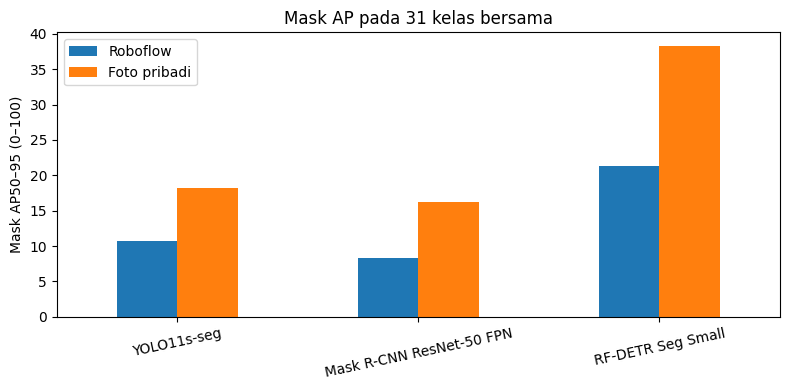

In [11]:
domain_shift = (common_class_ap.groupby("model", sort=False)
                .agg(common_classes=("category_id", "nunique"),
                     test_ap=("mask_ap_test", "mean"),
                     personal_ap=("mask_ap_personal", "mean"),
                     common_gain_ap_points=("gain_ap_points", "mean"))
                .reset_index())
domain_shift.insert(1, "model_name", domain_shift["model"].map(model_labels))
domain_shift[["test_ap", "personal_ap"]] *= 100
domain_shift["original_gain_ap_points"] = [
    100 * (source_metrics[model, "personal"]["mask_ap"] - source_metrics[model, "test"]["mask_ap"])
    for model in domain_shift["model"]]
domain_shift.to_csv(REPORTS / "domain_shift_common_classes.csv", index=False)
display(domain_shift.round(2))

chart = domain_shift.set_index("model_name")[["test_ap", "personal_ap"]]
axes = chart.rename(columns={"test_ap": "Roboflow", "personal_ap": "Foto pribadi"}).plot.bar(
    rot=12, figsize=(8, 4), ylabel="Mask AP50–95 (0–100)")
axes.set_xlabel("")
axes.set_title(f"Mask AP pada {len(common_ids)} kelas bersama")
plt.tight_layout()
plt.savefig(REPORTS / "domain_shift_common_classes.png", dpi=150)
plt.show()


Perubahan AP pada kelas bersama mengendalikan perbedaan daftar kelas. Jumlah instance per kelas, komposisi adegan, dan cara anotasi masih dapat berbeda. Kolom dukungan ground truth di CSV per kelas membantu membaca selisih tersebut.


## 3. Lima kegagalan pada foto pribadi


### 3.1 Format prediksi dan overlap

Kelompokkan prediksi menurut gambar dan hitung Mask IoU setiap pasangan prediksi dan ground truth.


In [12]:
def read_predictions(path):
    with gzip.open(path, "rt", encoding="utf-8") as handle:
        return json.load(handle)

def by_image(rows):
    grouped = defaultdict(list)
    for row in rows:
        assert row["image_id"] in image_files and row["category_id"] in CLASS_NAMES
        assert 0 <= row["score"] <= 1
        grouped[row["image_id"]].append(row)
    return grouped

def make_image_record(image, detections):
    targets = ground_truth[image["id"]]
    detections = sorted(detections, key=lambda row: -row["score"])
    height, width = image["height"], image["width"]
    gt_rles = [polygon_rle(row["segmentation"], height, width) for row in targets]
    pred_rles = [polygon_rle(row["segmentation"], height, width) for row in detections]
    overlaps = (mask_utils.iou(pred_rles, gt_rles, [0] * len(gt_rles))
                if pred_rles and gt_rles else np.zeros((len(pred_rles), len(gt_rles))))
    labels = np.equal.outer([row["category_id"] for row in detections], [row["category_id"] for row in targets])
    return {"targets": targets, "predictions": detections, "overlaps": overlaps, "same_class": labels}


### 3.2 Pencocokan instance

Cocokkan satu prediksi dengan maksimal satu ground truth berkelas sama, dari confidence tertinggi.


In [13]:
def match_detections(record, confidence):
    found = {}
    active = 0
    for index, row in enumerate(record["predictions"]):
        if row["score"] < confidence:
            break
        active += 1
        eligible = record["same_class"][index] & (record["overlaps"][index] >= MATCH_IOU)
        candidates = [target for target in np.flatnonzero(eligible) if target not in found]
        if candidates:
            best = max(candidates, key=lambda target: record["overlaps"][index, target])
            found[best] = index
    return found, active - len(found)

records, baseline_matches = {}, {}
for model, folder in files_by_model.items():
    predictions = by_image(read_predictions(folder / "predictions_personal.json.gz"))
    records[model] = {iid: make_image_record(item, predictions[iid]) for iid, item in image_files.items()}
    baseline_matches[model] = {iid: match_detections(record, BASELINE_CONFIDENCE)
                               for iid, record in records[model].items()}
    print(model_labels[model], sum(map(len, predictions.values())), "mask prediksi tersimpan")


YOLO11s-seg 4071 mask prediksi tersimpan
Mask R-CNN ResNet-50 FPN 5410 mask prediksi tersimpan
RF-DETR Seg Small 5600 mask prediksi tersimpan


### 3.3 Identifikasi kegagalan

Klasifikasikan ground truth yang belum cocok memakai kelas prediksi dan besarnya overlap.


In [14]:
def best_overlap(record, target, confidence, min_iou=0.10):
    overlaps = record["overlaps"][:, target]
    indices = [i for i, row in enumerate(record["predictions"])
               if row["score"] >= confidence and overlaps[i] >= min_iou]
    return max(indices, key=lambda i: overlaps[i], default=None)

def categorize(record, target, confidence):
    overlap = record["overlaps"][:, target]
    same_class = record["same_class"][:, target]
    active = np.array([row["score"] >= confidence for row in record["predictions"]], dtype=bool)
    options = [(active & same_class & (overlap >= MATCH_IOU), "Prediksi cocok dengan instance lain"),
               (active & ~same_class & (overlap >= MATCH_IOU), "Salah kelas"),
               (active & same_class & (overlap >= 0.10), "Mask kurang tumpang tindih")]
    for eligible, name in options:
        if eligible.any():
            index = int(np.argmax(np.where(eligible, overlap, -1)))
            return name, index
    return "Objek terlewat pada threshold awal", best_overlap(record, target, confidence)

candidates = []
for model, images in records.items():
    for iid, record in images.items():
        matches, _ = baseline_matches[model][iid]
        for target, ann in enumerate(record["targets"]):
            if target in matches:
                continue
            failure, candidate = categorize(record, target, BASELINE_CONFIDENCE)
            iou = float(record["overlaps"][candidate, target]) if candidate is not None else 0.0
            candidates.append({"model": model, "image_id": iid, "target": target, "gt_id": ann["id"],
                               "gt_category_id": ann["category_id"], "baseline_candidate": candidate,
                               "failure": failure, "baseline_iou": iou, "area": ann["area"]})


### 3.4 Kunci empat kasus sebelumnya

Ambil studi kasus dari hasil v2 dan cocokkan kembali dengan prediksi sumber.


In [15]:
previous_reports = WORK / "reports/all_classes" / PREVIOUS_ANALYSIS_RUN
previous_config = read_json(previous_reports / "analysis_config.json")
assert previous_config["source_run"] == SOURCE_RUN and previous_config["personal_dataset_id"] == personal_id
assert previous_config["baseline_confidence"] == BASELINE_CONFIDENCE
assert previous_config["low_confidence"] == LOW_CONFIDENCE and previous_config["mask_iou"] == MATCH_IOU
prior = pd.read_csv(previous_reports / "failure_case_notes.csv").sort_values("case")
assert prior["case"].tolist() == list(range(1, CASE_COUNT + 1)) and prior["file_name"].is_unique
discard = prior[prior["file_name"] == EXCLUDED_CASE_PHOTO]
assert len(discard) == 1, "Daftar studi kasus v2 harus memuat foto v2_023 sekali."
case_lookup = {(row["model"], image_files[row["image_id"]]["file_name"], row["gt_id"]): row for row in candidates}
fixed_cases = {}
for row in prior[prior["file_name"] != EXCLUDED_CASE_PHOTO].itertuples(index=False):
    key = (row.model, row.file_name, row.gt_id)
    if key not in case_lookup:
        raise ValueError(f"Prediksi sumber berbeda untuk kasus {row.case}: {row.file_name}")
    fixed_cases[row.case] = case_lookup[key]


### 3.5 Pilih satu foto pengganti

Cari kegagalan pada mask objek dengan label yang telah diperiksa secara visual.


In [16]:
reviewed_source_ids = {1, 265, 401, 21, 278, 405, 408, 33, 35, 420, 41, 425, 43, 182, 310, 59, 319, 64, 65, 192, 322, 323, 452, 70, 453, 72, 329, 204, 332, 78, 460, 208, 464, 82, 83, 212, 213, 342, 469, 472, 348, 349, 476, 478, 355, 356, 483, 489, 366, 495, 370, 243, 252}
assert len(raw_personal["annotations"]) == len(personal_data["annotations"])
source_ids = {ann["id"]: before["id"] for before, ann in zip(raw_personal["annotations"], personal_data["annotations"])}
previous_files = set(prior["file_name"])
alternatives = [row for row in candidates if source_ids[row["gt_id"]] in reviewed_source_ids
                and image_files[row["image_id"]]["file_name"] not in previous_files]
if not alternatives:
    raise RuntimeError("Belum ada kegagalan pada daftar mask dengan label yang telah diperiksa.")

failure_counts = Counter(row["failure"] for row in fixed_cases.values())
class_counts = Counter(row["gt_category_id"] for row in fixed_cases.values())
removed = discard.iloc[0]
replacement = min(alternatives, key=lambda row: (
    row["model"] != removed["model"], failure_counts[row["failure"]], class_counts[row["gt_category_id"]],
    -row["baseline_iou"], -row["area"], row["image_id"], row["gt_id"]))
final_cases = {**fixed_cases, int(removed["case"]): replacement}
chosen = [final_cases[number] for number in sorted(final_cases)]

replacement_file = image_files[replacement["image_id"]]["file_name"]
print(f"Kasus {int(removed['case'])}: {EXCLUDED_CASE_PHOTO} diganti dengan {replacement_file}.")
write_json(REPORTS / "case_replacement.json", {
    "case": int(removed["case"]), "previous_file": EXCLUDED_CASE_PHOTO,
    "replacement_file": replacement_file, "model": replacement["model"],
    "source_annotation_id": source_ids[replacement["gt_id"]],
    "class_name": CLASS_NAMES[replacement["gt_category_id"]], "failure": replacement["failure"]})

selection_table = pd.DataFrame(chosen)
selection_table["file_name"] = selection_table["image_id"].map(lambda iid: image_files[iid]["file_name"])
selection_table["class_name"] = selection_table["gt_category_id"].map(CLASS_NAMES)
display(selection_table[["model", "file_name", "class_name", "failure", "baseline_iou"]].round(3))


Kasus 4: indoor_5054241018_v2_023.jpeg diganti dengan indoor_5054241018_v2_029.jpeg.


,model,file_name,class_name,failure,baseline_iou
0,rfdetr,indoor_5054241018_v2_025.jpeg,bowl,Salah kelas,0.994
1,yolo11,indoor_5054241018_v2_019.jpeg,wall-other-merged,Mask kurang tumpang tindih,0.497
2,maskrcnn,indoor_5054241018_v2_003.jpeg,table-merged,Objek terlewat pada threshold awal,0.492
3,rfdetr,indoor_5054241018_v2_029.jpeg,cup,Salah kelas,0.990
4,yolo11,indoor_5054241018_016.jpeg,book,Mask kurang tumpang tindih,0.492


## 4. Eksperimen confidence threshold


### 4.1 Dampak pada 56 foto

Ulangi pencocokan dengan confidence lebih rendah dan hitung perubahan TP, FP, FN, precision, serta recall.


In [17]:
low_matches = {model: {iid: match_detections(record, LOW_CONFIDENCE) for iid, record in by_id.items()}
               for model, by_id in records.items()}

def threshold_result(model, matches_by_image, confidence):
    tp = sum(len(matches) for matches, _ in matches_by_image.values())
    fp = sum(false_pos for _, false_pos in matches_by_image.values())
    total = len(personal_data["annotations"])
    return {"model": model, "model_name": model_labels[model], "confidence": confidence, "match_iou": MATCH_IOU,
            "tp": tp, "fp": fp, "fn": total - tp,
            "precision": tp / (tp + fp) if tp + fp else 0.0, "recall": tp / total}

threshold_table = pd.DataFrame([
    threshold_result(model, matches[model], cutoff)
    for model in SOURCE_MODELS
    for cutoff, matches in [(BASELINE_CONFIDENCE, baseline_matches), (LOW_CONFIDENCE, low_matches)]
])
threshold_table.to_csv(REPORTS / "threshold_experiment.csv", index=False)
display(threshold_table.round(3))


,model,model_name,confidence,match_iou,tp,fp,fn,precision,recall
0,yolo11,YOLO11s-seg,0.25,0.5,181,257,249,0.413,0.421
1,yolo11,YOLO11s-seg,0.05,0.5,224,858,206,0.207,0.521
2,maskrcnn,Mask R-CNN ResNet-50 FPN,0.25,0.5,104,417,326,0.200,0.242
3,maskrcnn,Mask R-CNN ResNet-50 FPN,0.05,0.5,145,1186,285,0.109,0.337
4,rfdetr,RF-DETR Seg Small,0.25,0.5,270,472,160,0.364,0.628
5,rfdetr,RF-DETR Seg Small,0.05,0.5,333,3740,97,0.082,0.774


### 4.2 Dampak pada lima kegagalan

Catat apakah mask yang benar muncul dan kelompokkan temuan berdasarkan bukti model pada tiap kasus.


In [18]:
def candidate_details(record, index, target):
    if index is None:
        return {"class": None, "score": None, "iou": None}
    row = record["predictions"][index]
    return {"class": CLASS_NAMES[row["category_id"]], "score": row["score"],
            "iou": float(record["overlaps"][index, target])}

def diagnose(failure, recovered):
    if recovered:
        return "Mask berkelas benar cocok setelah ambang confidence diturunkan."
    if failure == "Salah kelas":
        return "Mask ber-overlap tinggi terdeteksi, tetapi asosiasi kelas masih keliru."
    if failure == "Mask kurang tumpang tindih":
        return "Prediksi pada kelas yang benar tersedia dengan IoU di bawah syarat kecocokan."
    if failure == "Prediksi cocok dengan instance lain":
        return "Prediksi kelas yang benar belum mencakup kedua instance secara terpisah."
    return "Prediksi tersimpan belum memberikan mask yang cocok pada kedua ambang."

case_rows = []
for number, case in enumerate(chosen, 1):
    model, iid, target = case["model"], case["image_id"], case["target"]
    record = records[model][iid]
    low_for_image, _ = low_matches[model][iid]
    recovered = target in low_for_image
    after = low_for_image[target] if recovered else best_overlap(record, target, LOW_CONFIDENCE)
    case["low_candidate"] = after
    before = candidate_details(record, case["baseline_candidate"], target)
    after_details = candidate_details(record, after, target)
    case_rows.append({"case": number, "model": model, "file_name": image_files[iid]["file_name"],
                      "gt_id": case["gt_id"], "ground_truth_class": CLASS_NAMES[case["gt_category_id"]],
                      "failure": case["failure"], "recovered_at_lower_confidence": recovered,
                      **{f"before_{key}": value for key, value in before.items()},
                      **{f"after_{key}": value for key, value in after_details.items()},
                      "finding": diagnose(case["failure"], recovered)})


### 4.3 Rekap hasil eksperimen

Simpan kesimpulan berbasis pengamatan dan konteks arsitektur sebagai bahan penulisan laporan.


In [19]:
architectures = {"yolo11": "Class confidence dan mask dari prototype segmentation.",
                 "maskrcnn": "Klasifikasi RoI serta mask head per RoI.",
                 "rfdetr": "Skor kelas dan mask yang berasosiasi dengan object query."}
case_table = pd.DataFrame(case_rows)
case_table["mechanism_to_review"] = case_table["model"].map(architectures)
case_table.to_csv(REPORTS / "failure_case_notes.csv", index=False)
display(case_table[["case", "ground_truth_class", "model", "failure",
                    "recovered_at_lower_confidence", "finding"]])
write_json(REPORTS / "analysis_config.json", {
    "source_run": SOURCE_RUN, "baseline_runs": SOURCE_MODELS, "personal_dataset_id": personal_id,
    "roboflow_dataset_id": source_manifest["roboflow_dataset_id"], "common_category_ids": common_ids,
    "baseline_confidence": BASELINE_CONFIDENCE, "low_confidence": LOW_CONFIDENCE, "mask_iou": MATCH_IOU})


,case,ground_truth_class,model,failure,recovered_at_lower_confidence,finding
0,1,bowl,rfdetr,Salah kelas,True,Mask berkelas benar cocok setelah ambang confi...
1,2,wall-other-merged,yolo11,Mask kurang tumpang tindih,False,Prediksi pada kelas yang benar tersedia dengan...
2,3,table-merged,maskrcnn,Objek terlewat pada threshold awal,False,Prediksi tersimpan belum memberikan mask yang ...
3,4,cup,rfdetr,Salah kelas,False,"Mask ber-overlap tinggi terdeteksi, tetapi aso..."
4,5,book,yolo11,Mask kurang tumpang tindih,True,Mask berkelas benar cocok setelah ambang confi...


Percobaan ini mengukur pengaruh confidence threshold terhadap pemilihan mask yang sudah diekspor. Prediksi yang tersaring sebelum ekspor, termasuk oleh aturan internal model dan batas deteksi per gambar, berada di luar percobaan. Gunakan perubahan TP dan FP untuk menilai trade-off. Hubungkan kasus mask yang kurang cocok dengan cara model membangun mask sebagai hipotesis untuk diperiksa dari visualisasi.


## 5. Visualisasi per kasus


### 5.1 Overlay mask

Tampilkan warna pada mask fokus dan gunakan crop ground truth yang sama pada semua panel per kasus.


In [20]:
def draw_mask(axis, image, row, item, color, outline=None):
    axis.imshow(image)
    axis.axis("off")
    if row is not None:
        mask = mask_from_annotation(row, item)
        axis.imshow(np.ma.masked_equal(mask, 0), cmap=ListedColormap([color]), alpha=0.45)
    if outline is not None:
        axis.contour(outline, levels=[0.5], colors=["white"], linewidths=0.8, linestyles="dashed")

def crop_limits(ann, item):
    x, y, width, height = ann["bbox"]
    padding = max(48, 0.55 * max(width, height))
    return ((max(0, x - padding), min(item["width"], x + width + padding)),
            (min(item["height"], y + height + padding), max(0, y - padding)))

def prediction_title(record, index, target, confidence):
    info = candidate_details(record, index, target)
    if index is None:
        return f"Confidence ≥ {confidence:.2f}\nTidak ada kandidat ber-overlap"
    return (f"Confidence ≥ {confidence:.2f}\n{info['class']} · score {info['score']:.2f} · IoU {info['iou']:.2f}")


### 5.2 Simpan lima panel kegagalan

Tampilkan foto utuh, ground truth, dan kandidat prediksi pada kedua threshold.


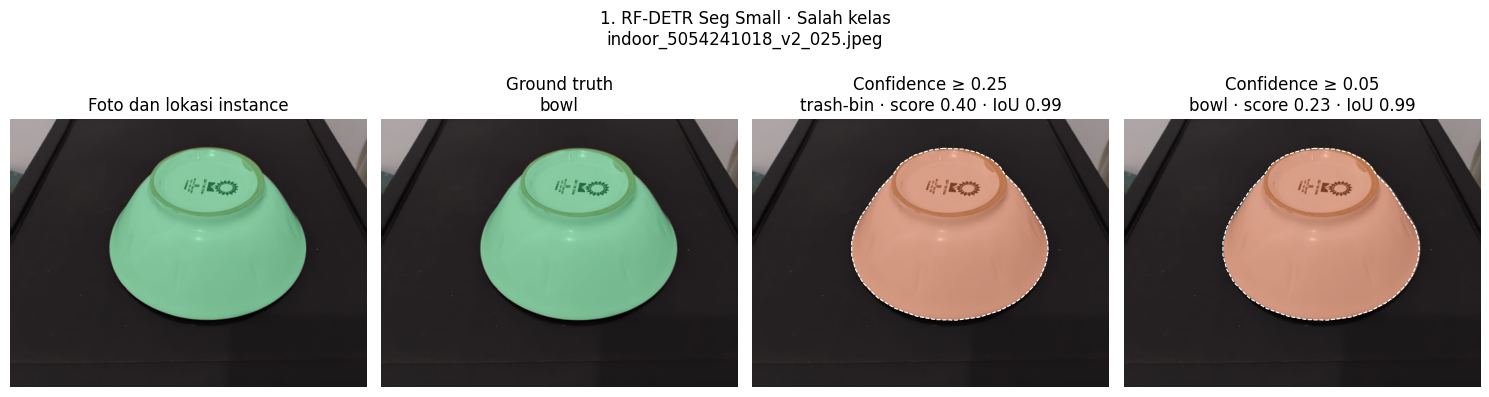

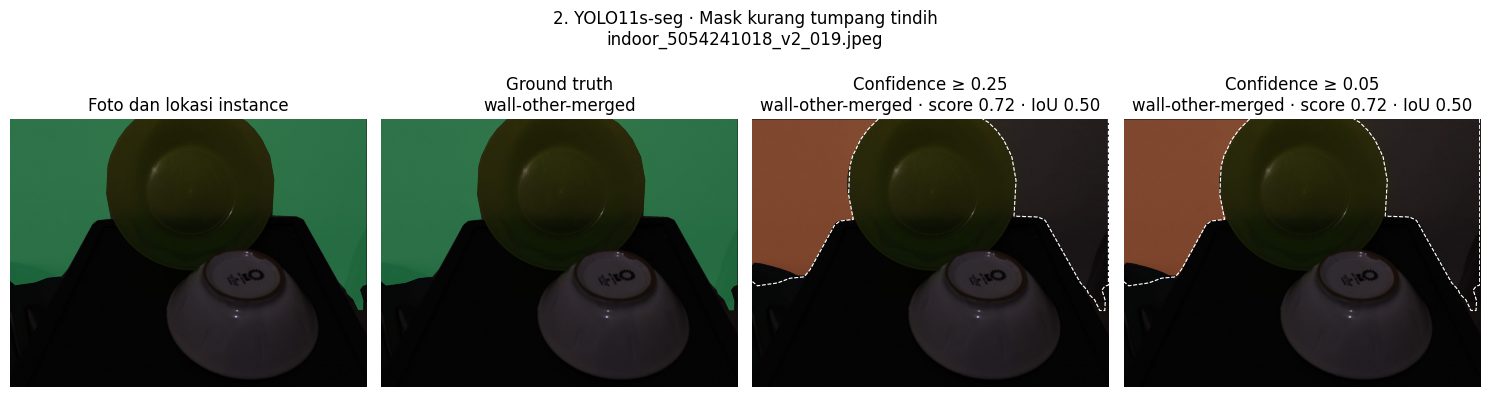

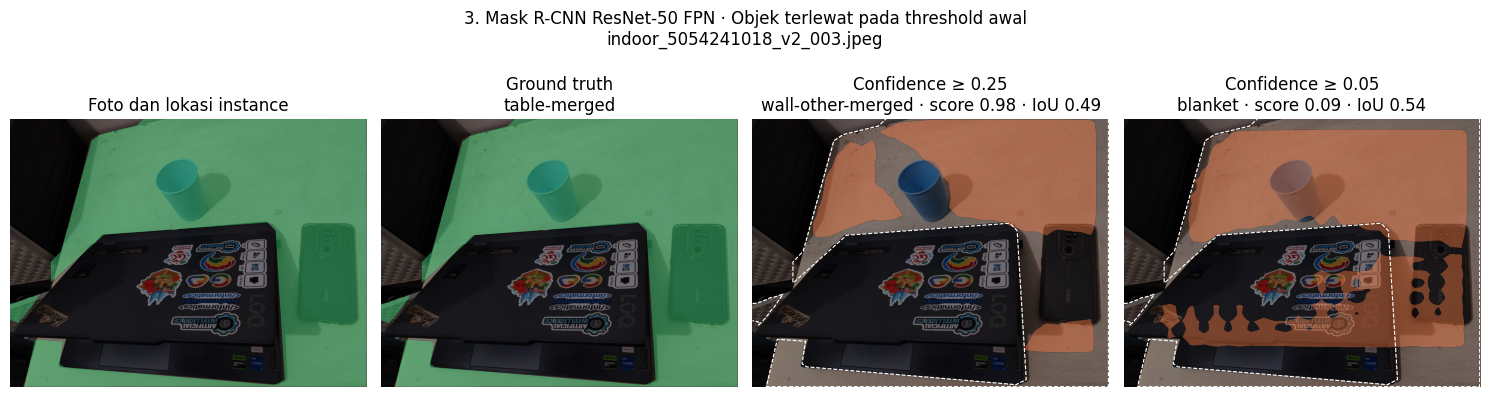

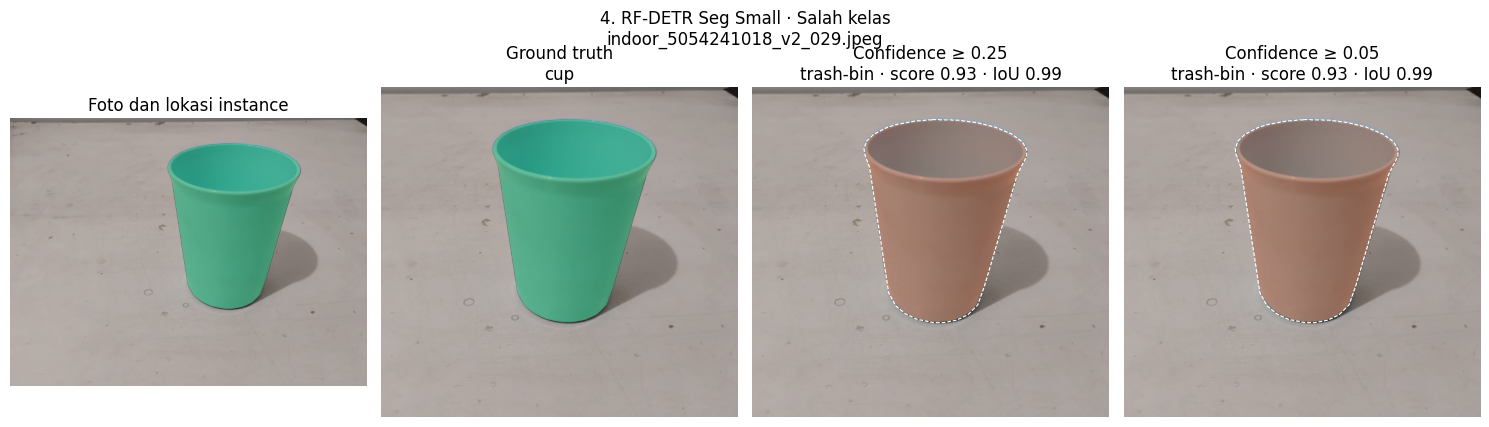

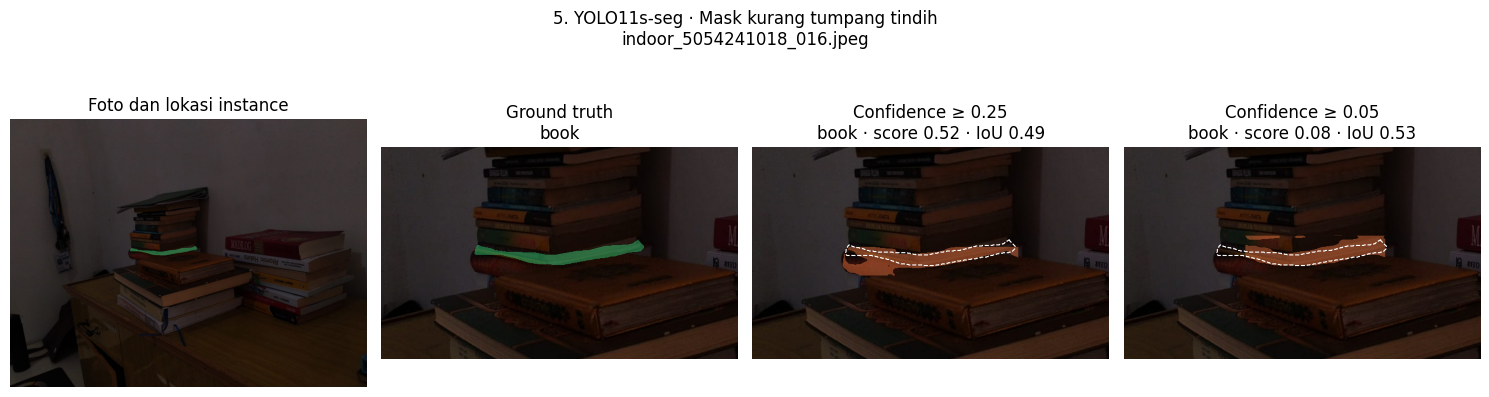

Laporan tersimpan: /content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/outputs/reports/all_classes/analisis_personal56_v2_kasus_revisi


In [21]:
figure_dir = REPORTS / "failure_cases"
figure_dir.mkdir(exist_ok=True)
for number, case in enumerate(chosen, 1):
    model, iid, target = case["model"], case["image_id"], case["target"]
    item = image_files[iid]
    record = records[model][iid]
    gt = record["targets"][target]
    with Image.open(PHOTO_DIR / item["file_name"]) as photo:
        assert photo.size == (item["width"], item["height"])
        image = np.asarray(photo.convert("RGB"))
    outline = mask_from_annotation(gt, item)
    figure, axes = plt.subplots(1, 4, figsize=(15, 4.5))
    draw_mask(axes[0], image, gt, item, "#38d97c")
    axes[0].set_title("Foto dan lokasi instance")
    draw_mask(axes[1], image, gt, item, "#38d97c")
    axes[1].set_title(f"Ground truth\n{CLASS_NAMES[gt['category_id']]}")
    for axis, index, cutoff in [(axes[2], case["baseline_candidate"], BASELINE_CONFIDENCE),
                                 (axes[3], case["low_candidate"], LOW_CONFIDENCE)]:
        detected = record["predictions"][index] if index is not None else None
        draw_mask(axis, image, detected, item, "#f07842", outline=outline)
        axis.set_title(prediction_title(record, index, target, cutoff))
    for axis in axes[1:]:
        xlim, ylim = crop_limits(gt, item)
        axis.set_xlim(xlim)
        axis.set_ylim(ylim)
    figure.suptitle(f"{number}. {model_labels[model]} · {case['failure']}\n{item['file_name']}")
    figure.tight_layout()
    figure.savefig(figure_dir / f"case_{number:02d}.png", dpi=150)
    plt.show()
    plt.close(figure)
print("Laporan tersimpan:", REPORTS)


Gunakan **domain_shift_common_classes.csv** untuk tabel perbandingan kelas bersama, **failure_case_notes.csv** dan **failure_cases/** untuk studi kasus, serta **threshold_experiment.csv** untuk menjelaskan perubahan recall dan false positive.
